# Quadratic bilevel problem — non-diagonal coupling

$$
F(w,\theta) = w^\top A\, w + \theta^\top B\, \theta \qquad\text{(upper)}
$$
$$
J(w,\theta) = w^\top C\, w + w^\top D\, \theta \qquad\text{(lower)}
$$

where $w,\theta\in\mathbb{R}^2$ and $A,B,C,D$ are $2\times 2$ **diagonal** matrices
you define explicitly below.

**Analytical optimum** (for $A,B,C$ with positive diagonals):
$$
w^*(\theta) = -\tfrac{1}{2}C^{-1}D\theta,
\qquad
\theta^* = 0, \quad w^* = 0.
$$
Convergence is tracked via $\|w_t\| + \|\theta_t\| \to 0$.

In [28]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt

import nondiag_lib
from nondiag_lib import (
    run_sweep, run_single, summarise, summary_table,
    iters_to_converge, problem_diagnostics, METHODS,
)

%load_ext autoreload
%autoreload 2

print('methods:', nondiag_lib.METHODS)
print('cpu count:', os.cpu_count())

COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
methods: ['PABLO', 'BOME', 'TSP', 'STABLE', 'AAL', 'PBGD-Free']
cpu count: 10


## Problem matrices — edit here

Define the diagonal entries of $A$, $B$, $C$, $D$.  
Rules of thumb:
- **$C$**: lower-level curvature; condition number $c_1/c_2$ controls how hard the inner problem is.
- **$D$**: coupling strength; larger entries amplify the bilevel interaction.
- **$A$**: upper-level curvature; scales the difficulty of the outer problem.
- **$B$**: direct upper-level regularisation on $\theta$.

In [29]:

# ── diagonal entries ─────────────────────────────────────────────────────────
a1, a2 = 1.0,  1.0    # A = diag(a1, a2)  upper-level w curvature
b1, b2 = 1.0,  1.0    # B = diag(b1, b2)  upper-level θ curvature
d1, d2 = 1.0,  1.0    # D = diag(d1, d2)  coupling matrix

A = np.diag([a1, a2])
B = np.diag([b1, b2])
C = A
D = np.diag([d1, d2])

# ── problem summary ───────────────────────────────────────────────────────────
M = problem_diagnostics(A, B, C, D)

Condition numbers:
  κ(A) = 1
  κ(B) = 1
  κ(C) = 1  ← lower-level curvature in w
  κ(D) = 1  ← coupling strength
Effective upper-level curvature M = ¼ D C⁻¹ A C⁻¹ D + B:
  diag(M) = [1.25 1.25]
  κ(M)    = 1
Analytical optimum: w* = 0,  θ* = 0
KKT Conditioning: 2.38


## Hyperparameters — edit here

One dict per algorithm.  Only the keys recognised by `nondiag_lib.build` matter;
unrecognised keys are silently ignored.

In [32]:
  
HPARAMS = {
    "PABLO": dict(lr=0.05, alpha=0.999, eps=1e-4, rho=0.1,lr_lambda=0.05, tau=0.01, y_rate=0.3, grad_clip=10., lambda_bound=10.0, total_steps=None),                              
    "BOME":      dict(lr=0.3,        opt="adam",  inner_steps=10, inner_lr=0.001,   eta=0.599484,  barrier="grad_norm"),
    "TSP":       dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.023208,  mu=0.5, theta=0.5, eta=0.059948, step=0.030971, omega=1.198969, lambda_init=1.0),
    "STABLE":    dict(lr_w=0.01, lr_theta=0.01, tau=0.1,  mu_g=0.01,    C_gxy=10.0),
    "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.03593814, rho0=0.0, alpha=3.594e-5,  eps=1e-5, tau=0.01),
    "PBGD-Free": dict(gamma=100.0,   eta=0.021544, eta_gamma=0.01,   K=1),
}

## Sweep settings

In [33]:
METHODS_RUN = ["PABLO", "BOME", "TSP", "STABLE", "AAL", "PBGD-Free"]

N_ITERS  = 1000          # iterations per run
GRID_N   = 10            # grid_n × grid_n starting points
GRID_LO  = -2.0          # scalar w₀ and θ₀ range
GRID_HI  =  2.0
ERR_TOL  = 1e-3          # convergence: ‖w‖ < tol AND ‖θ‖ < tol
N_JOBS   = max(1, (os.cpu_count() or 2) - 1)

print(f'{GRID_N**2} starting points, {N_ITERS} iterations, '
      f'{len(METHODS_RUN) * GRID_N**2} total runs')

100 starting points, 1000 iterations, 600 total runs


## Quick single-run test

Run each method for a few steps from a single start to check nothing crashes
before committing to the full sweep.

method                LL          UL  diverged
---------------------------------------------
PABLO             0.0002      0.0002  False
BOME              0.2772      0.2772  False
TSP               0.0204      0.1718  False
STABLE            1.6877      2.0680  False
AAL               1.3846      1.3859  False
PBGD-Free         1.1477      1.0279  False
dict_keys(['diverged', 'error', 'w', 'theta', 'ul_loss', 'll_loss'])


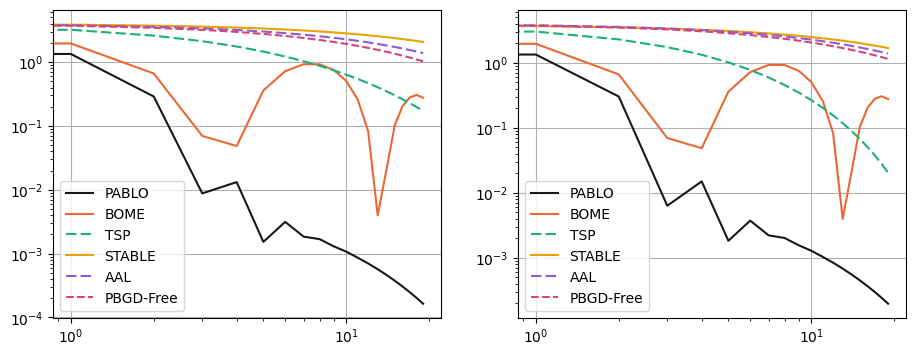

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
print(f"{'method':<12}  {'LL':>10}  {'UL':>10}  diverged")
print("-" * 45)
for m in METHODS_RUN:
    r = run_single(m, HPARAMS[m], A, B, C, D, w0=1.0, theta0=1.0, n_iters=20)
    if r['diverged']:
        print(f"{m:<12}  {'—':>10}  {'—':>10}  True  ({r['error']})")
    else:
        print(f"{m:<12}  {r['ll_loss'][-1]:>10.4f}  {r['ul_loss'][-1]:>10.4f}  False")
    ax[0].loglog(r['ul_loss'], label=m,color=COLOURS[m],linestyle=LINESTYLES[m],)
    ax[1].loglog(r['ll_loss'], label=m,color=COLOURS[m],linestyle=LINESTYLES[m],)
# ax[1].set_xlabel(r'$\kappa$')
# ax[1].set_ylabel('Iteration Complexity')
ax[1].grid(True)
# ax[0].set_xlabel(r'$a_1$')
# ax[0].set_ylabel('Iteration Complexity')
ax[0].grid(True)
ax[0].legend()
ax[1].legend()
print(r.
keys())

## Run sweep

In [6]:
# configs = {m: HPARAMS[m] for m in METHODS_RUN}

# t0 = time.time()
# sweep = run_sweep(
#     configs, A, B, C, D,
#     grid_lo=GRID_LO, grid_hi=GRID_HI, grid_n=GRID_N,
#     n_iters=N_ITERS, n_jobs=N_JOBS,
# )
# print(f"\nDone in {time.time()-t0:.1f}s")

# sm = summarise(sweep, tol=ERR_TOL)
# print()
# print(summary_table(sm, order=METHODS_RUN))

In [45]:
HPARAMS_TUNED = {
    # a1=0.05  |  PABLO=14  BOME=143  TSP=98  STABLE=370  AAL=68  PBGD-Free=40
    0.05: {
        # "PABLO": dict(lr=0.176556, alpha=0.99, eps=1e-06, rho=0.52143, lr_lambda=0.943797, tau=0.000154296, y_rate=0.3, grad_clip=None, lambda_bound=10.0, total_steps=None),
        "PABLO": dict({'lr': 0.1736030932205139, 'alpha': 0.99, 'eps': 1e-06, 'rho': 0.09183589566020707, 'lr_lambda': 0.903181984980719, 'tau': 6.289046871109941e-05, 'y_rate': 0.7, 'grad_clip': None, 'lambda_bound': 1.0, 'total_steps': None}),
        "BOME": dict(lr=0.153703, opt='adam', inner_steps=50, inner_lr=0.000901402, eta=0.638095, barrier='grad_norm'),
        "TSP": dict(gamma=0.300897, delta=0.0, p=0.005, dual_tau=0.0914508, mu=0.5, theta=0.3, eta=0.176643, step=0.23874, omega=0.5, lambda_init=1.0),
        "STABLE": dict(lr_w=0.2, lr_theta=0.1, tau=0.2, mu_g=0.00282579, C_gxy=50.0),
        "AAL": dict(L_f=1.12727, L_grad_g=1.12727, L_H=0.90182, gamma=0.00786055, rho0=0.0, alpha=0.000144849, eps=1e-05, tau=0.05),
        "PBGD-Free": dict(gamma=196.454, eta=0.471654, eta_gamma=0.2, K=10),
    },
    # a1=0.1  |  PABLO=14  BOME=136  TSP=70  STABLE=178  AAL=39  PBGD-Free=20
    0.1: {
        # "PABLO": dict(lr=0.0468879, alpha=0.999, eps=1e-06, rho=0.0445951, lr_lambda=0.536198, tau=0.000728286, y_rate=0.3, grad_clip=None, lambda_bound=5.0, total_steps=None),
        "PABLO": dict({'lr': 0.296513174397227, 'alpha': 0.999, 'eps': 1e-06, 'rho': 0.3415222725801353, 'lr_lambda': 1.469836909039238, 'tau': 0.00014428860066655966, 'y_rate': 0.5, 'grad_clip': None, 'lambda_bound': 5.0, 'total_steps': None}),
        "BOME": dict(lr=0.142009, opt='adam', inner_steps=50, inner_lr=7.80578e-05, eta=0.58292, barrier='grad_norm'),
        "TSP": dict(gamma=9.90834, delta=0.0, p=0.005, dual_tau=0.195647, mu=0.7, theta=0.3, eta=0.0131642, step=0.5, omega=1.5, lambda_init=1.0),
        "STABLE": dict(lr_w=0.2, lr_theta=0.1, tau=0.5, mu_g=0.00732406, C_gxy=5.0),
        "AAL": dict(L_f=1.25485, L_grad_g=0.627423, L_H=0.627423, gamma=0.00299612, rho0=0.0, alpha=6.95752e-05, eps=1e-05, tau=0.005),
        "PBGD-Free": dict(gamma=347.222, eta=0.5, eta_gamma=0.2, K=10),
    },
    # a1=0.5  |  PABLO=11  BOME=129  TSP=16  STABLE=29  AAL=8  PBGD-Free=5
    0.5: {
        "PABLO": dict(lr=0.0577865, alpha=0.999, eps=1e-06, rho=0.148668, lr_lambda=0.516633, tau=0.000118046, y_rate=0.5, grad_clip=None, lambda_bound=10.0, total_steps=None),
        "BOME": dict(lr=0.153486, opt='adam', inner_steps=5, inner_lr=0.000448922, eta=0.51832, barrier='grad_norm'),
        "TSP": dict(gamma=0.0574024, delta=0.0, p=0.01, dual_tau=0.0178586, mu=0.5, theta=0.5, eta=0.0283542, step=0.5, omega=1.5, lambda_init=1.0),
        "STABLE": dict(lr_w=0.2, lr_theta=0.2, tau=0.1, mu_g=0.00296146, C_gxy=1.0),
        "AAL": dict(L_f=1.5821, L_grad_g=0.791049, L_H=1.26568, gamma=0.00448027, rho0=0.0, alpha=2.56723e-05, eps=1e-05, tau=0.01),
        "PBGD-Free": dict(gamma=643.085, eta=0.5, eta_gamma=0.2, K=10),
    },
    # a1=1.0  |  PABLO=8  BOME=123  TSP=8  STABLE=14  AAL=2  PBGD-Free=2
    1.0: {
        "PABLO": dict(lr=0.497389, alpha=0.999, eps=1e-06, rho=0.0100145, lr_lambda=0.308882, tau=0.000539899, y_rate=0.1, grad_clip=None, lambda_bound=1.0, total_steps=None),
        "BOME": dict(lr=0.243825, opt='adam', inner_steps=10, inner_lr=0.000136205, eta=0.190036, barrier='grad_norm'),
        "TSP": dict(gamma=5.1882, delta=0.0, p=0.005, dual_tau=0.00435947, mu=0.5, theta=0.3, eta=0.532922, step=0.309388, omega=0.5, lambda_init=1.0),
        "STABLE": dict(lr_w=0.2, lr_theta=0.4, tau=0.5, mu_g=0.177027, C_gxy=1.0),
        "AAL": dict(L_f=1.0, L_grad_g=2.0, L_H=0.5, gamma=0.496719, rho0=0.0, alpha=0.000109659, eps=1e-05, tau=0.001),
        "PBGD-Free": dict(gamma=1.0, eta=0.5, eta_gamma=0.2, K=5),
    },
    # a1=5.0  |  PABLO=12  BOME=122  TSP=32  STABLE=19  AAL=20  PBGD-Free=3
    5.0: {
        "PABLO": dict(lr=0.161844, alpha=0.99, eps=1e-06, rho=0.18252, lr_lambda=0.337828, tau=0.00192008, y_rate=0.5, grad_clip=None, lambda_bound=5.0, total_steps=None),
        "BOME": dict(lr=0.377662, opt='adam', inner_steps=5, inner_lr=0.000231269, eta=0.838398, barrier='grad_norm'),
        "TSP": dict(gamma=0.0802782, delta=0.0, p=0.001, dual_tau=0.0766332, mu=0.7, theta=0.5, eta=0.0777022, step=0.105161, omega=1.5, lambda_init=1.0),
        "STABLE": dict(lr_w=0.150806, lr_theta=0.301612, tau=0.2, mu_g=0.000681517, C_gxy=10.0),
        "AAL": dict(L_f=6.28351, L_grad_g=12.567, L_H=3.14176, gamma=0.037384, rho0=0.0, alpha=2.24783e-06, eps=1e-05, tau=0.005),
        "PBGD-Free": dict(gamma=29.8205, eta=0.5, eta_gamma=0.160017, K=10),
    },
    # a1=10.0  |  PABLO=16  BOME=119  TSP=110  STABLE=39  AAL=37  PBGD-Free=5
    10.0: {
        "PABLO": dict(lr=0.104029, alpha=0.999, eps=1e-06, rho=0.0847485, lr_lambda=0.256426, tau=0.00109738, y_rate=0.5, grad_clip=None, lambda_bound=5.0, total_steps=None),
        "BOME": dict(lr=0.153899, opt='adam', inner_steps=20, inner_lr=8.12263e-05, eta=0.619786, barrier='grad_norm'),
        "TSP": dict(gamma=0.8, delta=0.0, p=0.01, dual_tau=0.023, mu=0.5, theta=0.5, eta=0.06, step=0.031, omega=1.2, lambda_init=1.0),
        "STABLE": dict(lr_w=0.091503, lr_theta=0.183006, tau=0.05, mu_g=0.371423, C_gxy=200.0),
        "AAL": dict(L_f=10.9374, L_grad_g=21.8747, L_H=10.9374, gamma=0.0173001, rho0=0.0, alpha=7.51727e-06, eps=1e-05, tau=0.0005),
        "PBGD-Free": dict(gamma=183.613, eta=0.5, eta_gamma=0.0868297, K=10),
    },
    # a1=20.0  |  PABLO=20  BOME=117  TSP=260  STABLE=79  AAL=123  PBGD-Free=11
    20.0: {
        "PABLO": dict(lr=0.250504, alpha=0.99, eps=1e-06, rho=0.056856, lr_lambda=0.121464, tau=0.000383062, y_rate=0.1, grad_clip=None, lambda_bound=5.0, total_steps=None),
        "BOME": dict(lr=0.0624148, opt='adam', inner_steps=50, inner_lr=0.000136387, eta=0.731354, barrier='grad_norm'),
        "TSP": dict(gamma=7.75817, delta=0.0, p=0.01, dual_tau=0.146432, mu=0.3, theta=0.5, eta=0.00820663, step=0.0144437, omega=2.0, lambda_init=1.0),
        "STABLE": dict(lr_w=0.046946, lr_theta=0.046946, tau=0.05, mu_g=0.00607486, C_gxy=10.0),
        "AAL": dict(L_f=18.3612, L_grad_g=36.7224, L_H=18.3612, gamma=0.00387002, rho0=0.0, alpha=0.000198586, eps=1e-05, tau=0.0005),
        "PBGD-Free": dict(gamma=7.13965, eta=0.5, eta_gamma=0.0276123, K=10),
    },
    # a1=50.0  |  PABLO=40  BOME=111  TSP=—  STABLE=171  AAL=359  PBGD-Free=34
    50.0: {
        "PABLO": dict(lr=0.230685, alpha=0.999, eps=1e-06, rho=0.0914747, lr_lambda=0.128268, tau=0.00233828, y_rate=0.1, grad_clip=None, lambda_bound=10.0, total_steps=None),
        "BOME": dict(lr=0.96848, opt='adam', inner_steps=10, inner_lr=0.0023881, eta=0.704068, barrier='grad_norm'),
        "TSP": dict(gamma=0.198771, delta=0.0, p=0.05, dual_tau=0.006793, mu=0.7, theta=0.3, eta=0.0210997, step=0.00914991, omega=2.0, lambda_init=1.0),
        "STABLE": dict(lr_w=0.0195577, lr_theta=0.0391155, tau=0.5, mu_g=0.00875053, C_gxy=30.0),
        "AAL": dict(L_f=50.9227, L_grad_g=101.845, L_H=15.2768, gamma=0.0389692, rho0=0.0, alpha=2.03396e-05, eps=1e-05, tau=0.0005),
        "PBGD-Free": dict(gamma=393.835, eta=0.342279, eta_gamma=0.0102493, K=10),
    },
    # a1=100.0  |  PABLO=36  BOME=113  TSP=—  STABLE=363  AAL=—  PBGD-Free=132
    100.0: {
        "PABLO": dict(lr=0.146961, alpha=0.999, eps=1e-06, rho=0.00183697, lr_lambda=0.0256679, tau=0.000171737, y_rate=0.7, grad_clip=None, lambda_bound=1.0, total_steps=None),
        "BOME": dict(lr=0.444323, opt='adam', inner_steps=50, inner_lr=0.00391856, eta=0.078409, barrier='grad_norm'),
        "TSP": dict(gamma=0.8, delta=0.0, p=0.01, dual_tau=0.023, mu=0.5, theta=0.5, eta=0.06, step=0.031, omega=1.2, lambda_init=1.0),
        "STABLE": dict(lr_w=0.00905854, lr_theta=0.0181171, tau=0.1, mu_g=0.000804567, C_gxy=200.0),
        "AAL": dict(L_f=113.926, L_grad_g=113.926, L_H=113.926, gamma=0.750298, rho0=0.0, alpha=1.42868e-06, eps=1e-05, tau=0.05),
        "PBGD-Free": dict(gamma=300.505, eta=0.0584963, eta_gamma=0.00266663, K=10),
    },
}



B = np.diag([b1, b2])
D = np.diag([d1, d2])

N_ITERS = 1000
GRID_N = 2
sweep_results = {}

conditioning = {}
for a1, hparams in HPARAMS_TUNED.items():

    A = np.diag([a1, a2])
    C = A
    M, KKT_CURVE = problem_diagnostics(A, B, C, D, verbose=False)
    sweep = run_sweep(
        hparams, A, B, C, D,
        grid_lo=GRID_LO, grid_hi=GRID_HI, grid_n=GRID_N,
        n_iters=N_ITERS, n_jobs=N_JOBS,
    )
    sweep_results[a1] = summarise(sweep, tol=ERR_TOL)
    conditioning[a1] = np.linalg.cond(KKT_CURVE)



Condition numbers:
  κ(A) = 20
  κ(B) = 1
  κ(C) = 20  ← lower-level curvature in w
  κ(D) = 1  ← coupling strength
Effective upper-level curvature M = ¼ D C⁻¹ A C⁻¹ D + B:
  diag(M) = [6.   1.25]
  κ(M)    = 4.8
Analytical optimum: w* = 0,  θ* = 0
KKT Conditioning: 29.9

2×2 = 4 starts on [-2.0, 2.0]²;  1000 iters;  24 total runs
Condition numbers:
  κ(A) = 10
  κ(B) = 1
  κ(C) = 10  ← lower-level curvature in w
  κ(D) = 1  ← coupling strength
Effective upper-level curvature M = ¼ D C⁻¹ A C⁻¹ D + B:
  diag(M) = [3.5  1.25]
  κ(M)    = 2.8
Analytical optimum: w* = 0,  θ* = 0
KKT Conditioning: 13.9

2×2 = 4 starts on [-2.0, 2.0]²;  1000 iters;  24 total runs
Condition numbers:
  κ(A) = 2
  κ(B) = 1
  κ(C) = 2  ← lower-level curvature in w
  κ(D) = 1  ← coupling strength
Effective upper-level curvature M = ¼ D C⁻¹ A C⁻¹ D + B:
  diag(M) = [1.5  1.25]
  κ(M)    = 1.2
Analytical optimum: w* = 0,  θ* = 0
KKT Conditioning: 3.92

2×2 = 4 starts on [-2.0, 2.0]²;  1000 iters;  24 total runs
Con

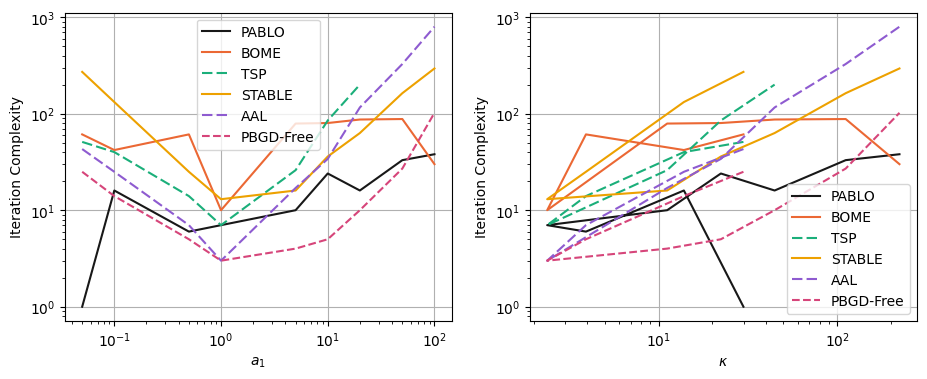

In [46]:
eps=1e-4

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m in METHODS_RUN:
    iter_comps = {}
    for a1, sw in sweep_results.items():
        ul_loss = sw[m]['median_curve_UL']
        ll_loss = sw[m]['median_curve_LL']
        if (ul_loss is not None) and (ll_loss is not None):
            iter_comps[a1] = np.argmax(((ul_loss<eps) & (ll_loss<eps)))+1
    ax[0].loglog(iter_comps.keys(), 
               iter_comps.values(), label=m,color=COLOURS[m],linestyle=LINESTYLES[m],)


    ax[1].loglog([conditioning[a1] for a1 in iter_comps.keys()], 
               iter_comps.values(), label=m,color=COLOURS[m],linestyle=LINESTYLES[m],)
ax[1].set_xlabel(r'$\kappa$')
ax[1].set_ylabel('Iteration Complexity')
ax[1].grid(True)
ax[0].set_xlabel(r'$a_1$')
ax[0].set_ylabel('Iteration Complexity')
ax[0].grid(True)
ax[0].legend()
ax[1].legend()
plt.show()
# print(sweep_results[a1]['PABLO'].keys())

## Convergence table

First iteration $t$ where median $\|w_t\| < $ `ERR_TOL` **and** median $\|\theta_t\| < $ `ERR_TOL`.

In [8]:
itc = iters_to_converge(sm, tol_w=ERR_TOL, tol_theta=ERR_TOL)

print(f"Iterations to reach median ‖w‖ < {ERR_TOL:g}  AND  median ‖θ‖ < {ERR_TOL:g}")
print(f"  (— = not reached in {N_ITERS} iterations)\n")
for m in METHODS_RUN:
    v = itc[m]
    print(f"  {m:<12}  {'—' if np.isnan(v) else int(v)}")
print(HPARAMS)

NameError: name 'sm' is not defined

## Convergence curves

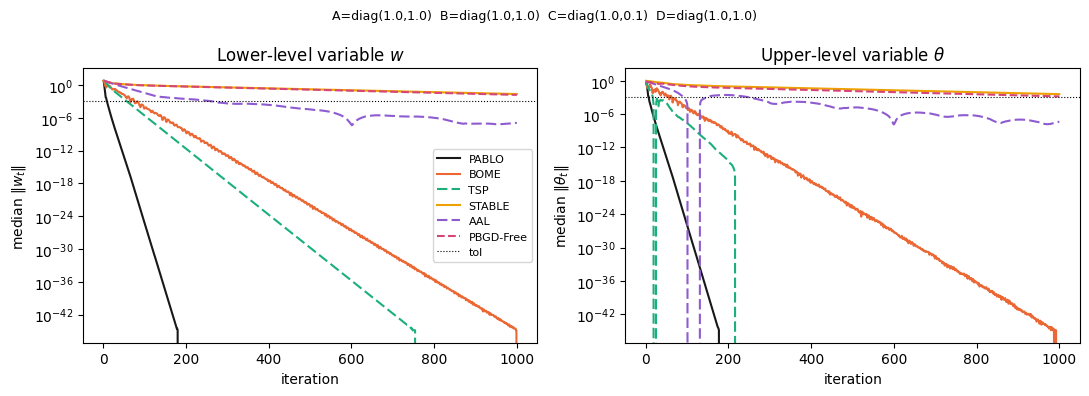

In [ ]:
iters = np.arange(1, N_ITERS + 1)

fig, (ax_w, ax_th) = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

for m in METHODS_RUN:
    s = sm[m]
    if s['median_curve_w_norm'] is None:
        continue
    ax_w.semilogy(iters, s['median_curve_UL'],label=m,color=COLOURS[m],linestyle=LINESTYLES[m],)
    ax_th.semilogy(iters, s['median_curve_LL'], label=m,color=COLOURS[m],linestyle=LINESTYLES[m],)

for ax in (ax_w, ax_th):
    ax.axhline(ERR_TOL, color='k', linestyle=':', linewidth=0.8, label='tol')
    ax.set_xlabel('iteration')

ax_w.set_ylabel(r'median $\|w_t\|$')
ax_th.set_ylabel(r'median $\|\theta_t\|$')
ax_w.set_title(r'Lower-level variable $w$')
ax_th.set_title(r'Upper-level variable $\theta$')
ax_w.legend(fontsize=8)

diag_str = (f'A=diag({a1},{a2})  B=diag({b1},{b2})  '
            f'C=diag({c1},{c2})  D=diag({d1},{d2})')
fig.suptitle(diag_str, fontsize=9)
plt.tight_layout()
plt.show()

## Losses

In [ ]:
fig, (ax_ll, ax_ul) = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

for m in METHODS_RUN:
    s = sm[m]
    if s['median_curve_LL'] is None:
        continue
    ll_pos = np.abs(s['median_curve_LL']) + 1e-30
    ul_pos = np.abs(s['median_curve_UL']) + 1e-30
    ax_ll.semilogy(iters, ll_pos, label=m)
    ax_ul.semilogy(iters, ul_pos, label=m)

ax_ll.set_ylabel(r'median $|J(w_t,\theta_t)|$')
ax_ul.set_ylabel(r'median $F(w_t,\theta_t)$')
ax_ll.set_title('Lower-level loss  $J$')
ax_ul.set_title('Upper-level loss  $F$')
for ax in (ax_ll, ax_ul):
    ax.set_xlabel('iteration')
ax_ll.legend(fontsize=8)
plt.tight_layout()
plt.show()